#### Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report

#202431036_Fathur Rasyid Irimawa

#### Membaca Dataset dan menampilkan datanya

In [2]:
df = pd.read_csv('final_test (NB).csv')
print(df.head())

#202431036_Fathur Rasyid Irimawa

   weight   age  height size
0      62  28.0  172.72   XL
1      59  36.0  167.64    L
2      61  34.0  165.10    M
3      65  27.0  175.26    L
4      62  45.0  172.72    M


#### Melihat informasi data

In [3]:
df.info()
print("\n" + "--- DESKRIPSI STATISTIK (describe()) ---")
print(df.describe())

#202431036_Fathur Rasyid Irimawa

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   weight  510 non-null    int64  
 1   age     509 non-null    float64
 2   height  510 non-null    float64
 3   size    510 non-null    object 
dtypes: float64(2), int64(1), object(1)
memory usage: 16.1+ KB

--- DESKRIPSI STATISTIK (describe()) ---
           weight         age      height
count  510.000000  509.000000  510.000000
mean    62.103922   34.182711  165.797255
std      9.766175    7.942214    6.737697
min     43.000000   17.000000  142.240000
25%     55.000000   29.000000  160.655000
50%     61.000000   32.000000  165.100000
75%     65.000000   38.000000  170.180000
max    113.000000   69.000000  187.960000


#### Memisahkan fitur numerik dan menampilkan jumlah dan daftarnya

In [4]:
numerical_features = df.select_dtypes(include=['number']).columns.tolist()
print(f"Jumlah fitur numerik: {len(numerical_features)}")
print(f"Daftar fitur numerik: {numerical_features}")

#202431036_Fathur Rasyid Irimawa

Jumlah fitur numerik: 3
Daftar fitur numerik: ['weight', 'age', 'height']


#### Memisahkan fitur kategorikal

In [5]:
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Jumlah fitur kategorikal: {len(categorical_features)}")
print(f"Daftar fitur kategorikal: {categorical_features}")

#202431036_Fathur Rasyid Irimawa

Jumlah fitur kategorikal: 1
Daftar fitur kategorikal: ['size']


#### Menampilkan isi unik setiap fitur kategorikal

In [6]:
for col in categorical_features:
    print(f"Kolom '{col}': {df[col].unique()} (Jumlah unik: {df[col].nunique()})")
    
    #202431036_Fathur Rasyid Irimawa

Kolom 'size': ['XL' 'L' 'M' 'S' 'XXS' 'XXXL'] (Jumlah unik: 6)


#### Mengubah fitur kategorikal menjadi angka

In [7]:
df_encoded = df.copy()
label_encoders = {}
for col in categorical_features:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    label_encoders[col] = le
df_encoded = df_encoded.dropna()
    
print(df_encoded.head())

#202431036_Fathur Rasyid Irimawa

   weight   age  height  size
0      62  28.0  172.72     3
1      59  36.0  167.64     0
2      61  34.0  165.10     1
3      65  27.0  175.26     0
4      62  45.0  172.72     1


#### Memisahkan fitur x dan target y

In [8]:
x = df_encoded.drop(columns=['size'])
y = df_encoded['size']

print("Contoh 5 Baris Fitur (x):")
print(x.head())
print("\nContoh 5 Baris Target (y):")
print(y.head())

#202431036_Fathur Rasyid Irimawa

Contoh 5 Baris Fitur (x):
   weight   age  height
0      62  28.0  172.72
1      59  36.0  167.64
2      61  34.0  165.10
3      65  27.0  175.26
4      62  45.0  172.72

Contoh 5 Baris Target (y):
0    3
1    0
2    1
3    0
4    1
Name: size, dtype: int32


#### Membagi data uji dan data latih

In [9]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)

print(f"Jumlah data latih (x_train): {x_train.shape[0]} baris")
print(f"Jumlah data uji (x_test): {x_test.shape[0]} baris")

#202431036_Fathur Rasyid Irimawa

Jumlah data latih (x_train): 381 baris
Jumlah data uji (x_test): 128 baris


#### Model GaussianNB() dan latih (fit)

In [10]:
model = GaussianNB()
model.fit(x_train, y_train)

#202431036_Fathur Rasyid Irimawa

GaussianNB()

#### Prediksi data latih dan data uji

In [11]:
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

#202431036_Fathur Rasyid Irimawa

#### Evaluasi data latih

Confusion Matrix (Training):
 [[12 26  4 26  1  1]
 [ 3 51 25 19  2  1]
 [ 0 18 43  0  5  0]
 [ 6 17  1 28  0  5]
 [ 0  2 20  0  7  0]
 [ 3  2  0 12  0 41]]

Classification Report (Training):
               precision    recall  f1-score   support

           0       0.50      0.17      0.26        70
           1       0.44      0.50      0.47       101
           2       0.46      0.65      0.54        66
           3       0.33      0.49      0.39        57
           4       0.47      0.24      0.32        29
           5       0.85      0.71      0.77        58

    accuracy                           0.48       381
   macro avg       0.51      0.46      0.46       381
weighted avg       0.50      0.48      0.47       381



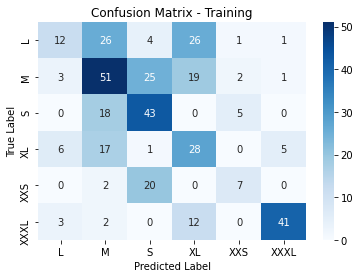

In [12]:
cm_train = confusion_matrix(y_train, y_pred_train)
print("Confusion Matrix (Training):\n", cm_train)
print("\nClassification Report (Training):\n", classification_report(y_train, y_pred_train))

plt.figure(figsize=(6, 4))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoders['size'].classes_, 
            yticklabels=label_encoders['size'].classes_)
plt.title("Confusion Matrix - Training")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

#202431036_Fathur Rasyid Irimawa

#### Evaluasi data uji

Confusion Matrix (Testing):
 [[ 5  6  2  5  0  1]
 [ 2 14 10  3  0  1]
 [ 1 11 11  1  0  0]
 [ 4  4  1  8  0  1]
 [ 0  1  4  0  3  0]
 [ 2  0  0  8  0 19]]

Classification Report (Testing):
               precision    recall  f1-score   support

           0       0.36      0.26      0.30        19
           1       0.39      0.47      0.42        30
           2       0.39      0.46      0.42        24
           3       0.32      0.44      0.37        18
           4       1.00      0.38      0.55         8
           5       0.86      0.66      0.75        29

    accuracy                           0.47       128
   macro avg       0.55      0.44      0.47       128
weighted avg       0.52      0.47      0.48       128



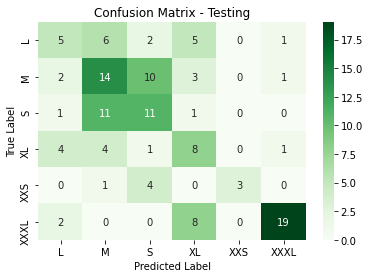

In [13]:
cm_test = confusion_matrix(y_test, y_pred_test)
print("Confusion Matrix (Testing):\n", cm_test)
print("\nClassification Report (Testing):\n", classification_report(y_test, y_pred_test))

plt.figure(figsize=(6, 4))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', 
            xticklabels=label_encoders['size'].classes_, 
            yticklabels=label_encoders['size'].classes_)
plt.title("Confusion Matrix - Testing")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

#202431036_Fathur Rasyid Irimawa

#### Uji dengan satu data baru

In [14]:
data_baru = pd.DataFrame([[60, 25.0, 168.0]], columns=['weight', 'age', 'height'])

prediksi_angka = model.predict(data_baru)
prediksi_teks = label_encoders['size'].inverse_transform(prediksi_angka)

print(data_baru)
print(f"Hasil Prediksi (Angka ter-encode): {prediksi_angka[0]}")
print(f"Hasil Prediksi (Kategori Asli): {prediksi_teks[0]}")

#202431036_Fathur Rasyid Irimawa

   weight   age  height
0      60  25.0   168.0
Hasil Prediksi (Angka ter-encode): 1
Hasil Prediksi (Kategori Asli): M
